In [244]:
import pandas as pd
import matplotlib.pyplot as plt

In [245]:
df = pd.read_csv("../data/ab-test.csv", encoding="utf-8")
# df.head()

In [246]:
DfTransformed = df.pivot(
    index=["uid", "group"], columns="time", values="diff"
).reset_index()
DfTransformed.head(2)

time,uid,group,after,before
0,user_1,test,-103.333333,-6.0
1,user_12,control,-75.000000,-103.0


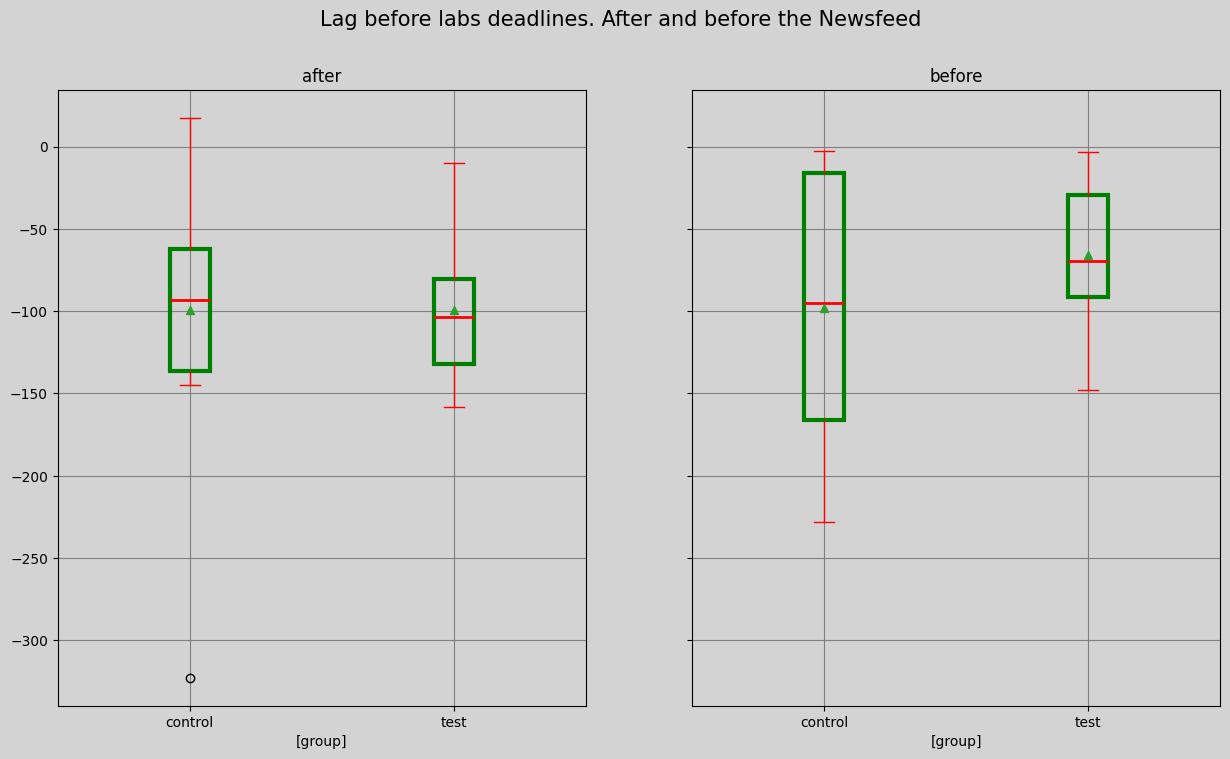

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8), sharey=True)

fig.suptitle("Lag before labs deadlines. After and before the Newsfeed", fontsize=15)
fig.patch.set_facecolor("lightgray")

style_options = {
    "patch_artist": True,
    "showmeans": True,
    "whiskerprops": {"color": "red"},
    "capprops": {"color": "red"},
    "medianprops": {
        "color": "red",
        "linewidth": 2,
    },
    "flierprops": {
        "marker": "o",
        "markerfacecolor": "none",
        "markeredgecolor": "black",
    },
}

for ax, stage in zip((ax1, ax2), ("after", "before")):
    graph = ax.boxplot(
        [
            DfTransformed[DfTransformed["group"] == "control"][stage],
            DfTransformed[DfTransformed["group"] == "test"][stage],
        ],
        tick_labels=["control", "test"],
        **style_options,
    )

    ax.set_title(stage)
    ax.set_xlabel("[group]")
    ax.set_facecolor("lightgray")
    ax.grid(True, color="gray")

    for box in graph["boxes"]:
        box.set_facecolor("none")
        box.set_edgecolor("green")
        box.set_linewidth(3)

plt.show()

## Каков IQR (межквартильный размах) контрольной группы до появления ленты новостей?
150